# Portfolio Growth and Risk Calculator

**Fairfield University | DATA 4000 · Python with AI**

This notebook is a small, editable portfolio calculator. You can compare ready-made examples or build your own mix by changing the weights in the settings cell. It uses historical ETF prices to estimate how each mix grew and how much it fluctuated over one chosen period.

This is an educational historical analysis, not a forecast or investment recommendation. Past performance does not guarantee future results. ETF tickers are examples of exposure to an asset class or sector; they are not the only available choices.

## Question

How did the historical growth and risk of a U.S.-stock-only portfolio compare with mixes that add international stocks, bonds, technology, or commodities?

We use three performance measures. **Total return** is the percent gain or loss over the whole period. **Annualized volatility** estimates the typical size of daily ups and downs scaled to a year; higher volatility means a bumpier ride, not necessarily a loss. **Maximum drawdown** is the largest peak-to-trough decline during the period. None of these measures captures every kind of investment risk.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

pd.set_option("display.float_format", "{:,.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Set the analysis period and portfolio options

### Available asset and sector examples

| Ticker | Example exposure | What it represents here |
|:--|:--|:--|
| `VTI` | U.S. stocks | Broad U.S. stock market |
| `VXUS` | International stocks | Stocks outside the United States |
| `BND` | Bonds | Broad U.S. investment-grade bonds |
| `XLK` | Technology | U.S. information technology sector |
| `XLE` | Energy | U.S. energy sector |
| `XLF` | Financials | U.S. financial sector |
| `XLV` | Health care | U.S. health care sector |
| `XLI` | Industrials | U.S. industrial sector |
| `XLY` | Consumer discretionary | U.S. consumer discretionary sector |
| `XLP` | Consumer staples | U.S. consumer staples sector |
| `XLU` | Utilities | U.S. utilities sector |
| `XLC` | Communication services | U.S. communication services sector |
| `XLRE` | Real estate | U.S. real estate sector |
| `XLB` | Materials | U.S. materials sector |
| `DBC` | Broad commodities | Commodity futures exposure; not the same as owning physical commodities |
| `GLD` | Gold | Gold-price exposure through a gold-backed fund |

### How to build a mix

In the code cell below, each portfolio is a dictionary of ticker-to-weight pairs. Weights are fractions: `0.25` means 25%. Change the `My custom portfolio` entries or add a new named dictionary to `PORTFOLIOS`. You are **not limited to the example tickers in the table**: you may enter a stock or ETF ticker supported by Yahoo Finance, such as `NVDA`. The notebook requests prices for every ticker actually used in your portfolios. Weights must total exactly 1.00 (100%); the next cell checks this and displays all of the tickers you selected. You can also change the analysis dates and starting investment.

Ready-made examples include a stock-only baseline, a balanced mix, a broader diversified mix, a technology-only portfolio, a broad-commodities-only portfolio, and a custom example made only from individual stocks: Apple (`AAPL`) 17%, Microsoft (`MSFT`) 17%, Amazon (`AMZN`) 16%, JPMorgan Chase (`JPM`) 17%, Costco (`COST`) 17%, and Coca-Cola (`KO`) 16%. This illustrative mix spans several businesses but is still concentrated in a small number of companies, and is not a recommendation for what a college student—or anyone else—should buy. Change its tickers or weights to explore other hypothetical mixes. Concentrated sector or commodity portfolios are comparison examples, not recommendations. VTI already holds many technology companies, so adding XLK increases technology concentration rather than introducing an entirely separate asset class.

For simplicity, the simulation buys each mix once at the start and does not rebalance it. Dividends and distributions are reflected approximately through auto-adjusted prices; taxes, fees, inflation, and transaction costs are not modeled.

In [2]:
START_DATE = "2021-01-01"
END_DATE = date.today().strftime("%Y-%m-%d")  # The end date is exclusive in yfinance.
INITIAL_INVESTMENT = 10_000

ASSETS = {
    "VTI": "U.S. total stock market",
    "VXUS": "International stocks",
    "BND": "U.S. investment-grade bonds",
    "XLK": "Technology sector",
    "XLE": "Energy sector",
    "XLF": "Financial sector",
    "XLV": "Health care sector",
    "XLI": "Industrials sector",
    "XLY": "Consumer discretionary sector",
    "XLP": "Consumer staples sector",
    "XLU": "Utilities sector",
    "XLC": "Communication services sector",
    "XLRE": "Real estate sector",
    "XLB": "Materials sector",
    "DBC": "Broad commodities futures exposure",
    "GLD": "Gold-price exposure",
}

PORTFOLIOS = {
    "U.S. stocks only": {"VTI": 1.00},
    "Balanced": {"VTI": 0.60, "VXUS": 0.20, "BND": 0.20},
    "Diversified stocks, bonds, and real assets": {
        "VTI": 0.35, "VXUS": 0.20, "BND": 0.25, "DBC": 0.10, "GLD": 0.10
    },
    "Technology sector only": {"XLK": 1.00},
    "Broad commodities only": {"DBC": 1.00},
    # Edit the values below (or add tickers) to test your own portfolio.
"My custom (example individual stocks)": {
    "AAPL": 0.17, "MSFT": 0.17, "AMZN": 0.16,
    "JPM": 0.17, "COST": 0.17, "KO": 0.16,
},
}

if INITIAL_INVESTMENT <= 0:
    raise ValueError("INITIAL_INVESTMENT must be greater than zero.")
if pd.Timestamp(START_DATE) >= pd.Timestamp(END_DATE):
    raise ValueError("START_DATE must be earlier than END_DATE.")

for portfolio_name, weights in PORTFOLIOS.items():
    if not weights:
        raise ValueError(f"{portfolio_name} must contain at least one ticker.")
    if any(not isinstance(ticker, str) or not ticker.strip() for ticker in weights):
        raise ValueError(f"{portfolio_name} contains an empty or invalid ticker name.")
    if not np.isclose(sum(weights.values()), 1.0):
        raise ValueError(f"Weights for {portfolio_name} must add up to 100%.")
    if any(weight < 0 for weight in weights.values()):
        raise ValueError(f"Weights for {portfolio_name} cannot be negative.")

TICKERS = list(dict.fromkeys(ticker for weights in PORTFOLIOS.values() for ticker in weights))
weight_table = pd.DataFrame(PORTFOLIOS).T.reindex(columns=TICKERS).fillna(0)
weight_table = weight_table.rename(columns={ticker: ASSETS.get(ticker, ticker) for ticker in TICKERS}) * 100
weight_table = weight_table.apply(lambda column: column.map("{:.0f}%".format))
weight_table

,U.S. total stock market,International stocks,U.S. investment-grade bonds,Broad commodities futures exposure,Gold-price exposure,Technology sector,AAPL,MSFT,AMZN,JPM,COST,KO
U.S. stocks only,100%,0%,0%,0%,0%,0%,0%,0%,0%,0%,0%,0%
Balanced,60%,20%,20%,0%,0%,0%,0%,0%,0%,0%,0%,0%
"Diversified stocks, bonds, and real assets",35%,20%,25%,10%,10%,0%,0%,0%,0%,0%,0%,0%
Technology sector only,0%,0%,0%,0%,0%,100%,0%,0%,0%,0%,0%,0%
Broad commodities only,0%,0%,0%,100%,0%,0%,0%,0%,0%,0%,0%,0%
My custom (example individual stocks),0%,0%,0%,0%,0%,0%,17%,17%,16%,17%,17%,16%


## 2. Download and check historical prices

This cell requests daily prices from Yahoo Finance through `yfinance`, so you need an internet connection. With `auto_adjust=True`, the returned `Close` prices are adjusted for distributions and stock splits. All portfolios use the same common trading dates so their comparisons are fair.

The sector ETFs are examples of U.S. industry sectors, while `DBC` tracks a basket of commodity futures and `GLD` provides gold-price exposure. Funds can differ in fees, holdings, and structure; commodity funds may not track spot commodity prices exactly.

In [3]:
raw_prices = yf.download(
    tickers=TICKERS,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
)

if raw_prices.empty:
    raise RuntimeError("No price data was returned. Check the connection, symbols, and dates.")

if isinstance(raw_prices.columns, pd.MultiIndex):
    if "Close" in raw_prices.columns.get_level_values(0):
        prices = raw_prices["Close"].copy()
    elif "Close" in raw_prices.columns.get_level_values(1):
        prices = raw_prices.xs("Close", axis=1, level=1).copy()
    else:
        raise KeyError("Could not find adjusted closing prices in the downloaded data.")
else:
    if "Close" not in raw_prices.columns:
        raise KeyError("Could not find adjusted closing prices in the downloaded data.")
    prices = raw_prices[["Close"]].rename(columns={"Close": TICKERS[0]})

prices = prices.reindex(columns=TICKERS).dropna(how="all")
missing_assets = prices.columns[prices.isna().all()].tolist()
if missing_assets:
    raise RuntimeError(f"No usable prices were returned for: {missing_assets}")

# Compare portfolios over the same dates so their results are comparable.
prices = prices.dropna()
if len(prices) < 2:
    raise RuntimeError("At least two common trading days are needed for the analysis.")

print(f"Common daily observations: {len(prices):,}")
print(f"Actual data period: {prices.index.min().date()} through {prices.index.max().date()}")
display(prices.head())

Common daily observations: 1,469
Actual data period: 2021-01-04 through 2026-11-06


Ticker,VTI,VXUS,BND,DBC,GLD,XLK,AAPL,MSFT,AMZN,JPM,COST,KO
Date,,,,,,,,,,,,
2021-01-04,177.2914,51.1209,73.3708,12.7214,182.3300,61.2803,125.6325,207.5654,159.3315,108.4594,357.5795,44.5271
2021-01-05,178.7236,51.8642,73.2458,13.0782,182.8700,61.6780,127.1858,207.7656,160.9255,109.0496,353.4313,44.0376
2021-01-06,180.3314,52.1430,72.9209,13.0956,179.9000,60.6143,122.9045,202.3784,156.9190,114.1701,348.0509,42.6366
2021-01-07,183.2236,52.3626,72.7710,13.1565,179.4800,62.2482,127.0984,208.1375,158.1080,117.9194,346.0756,42.1640
2021-01-08,184.1106,53.0299,72.7043,13.2609,173.3400,62.6506,128.1954,209.4056,159.1350,118.0496,347.9757,43.1092


## 3. Calculate portfolio growth and risk

Each portfolio starts with the same dollar amount. The code first divides each ETF's price by its price on the first shared trading day; this makes every ETF start at 1.0, so prices with different dollar values can be combined. It multiplies each normalized price series by its portfolio weight, adds the weighted series, then scales that result by the starting investment.

The resulting dollar-value lines are buy-and-hold portfolios: they do not reset back to the original weights. Total return compares the ending value with the starting value. Annualized return converts the full-period growth into an average yearly rate. Volatility is the standard deviation of daily portfolio returns multiplied by the square root of 252. Drawdown compares each day's value with the highest value reached up to that date; the most negative result is the maximum drawdown.

In [4]:
normalized_prices = prices / prices.iloc[0]
portfolio_values = pd.DataFrame(index=prices.index)

for portfolio_name, weights in PORTFOLIOS.items():
    weight_series = pd.Series(weights).reindex(prices.columns)
    portfolio_values[portfolio_name] = INITIAL_INVESTMENT * normalized_prices.mul(weight_series).sum(axis=1)

daily_returns = portfolio_values.pct_change().dropna()
trading_days_per_year = 252
summary_rows = []

for portfolio_name in portfolio_values.columns:
    values = portfolio_values[portfolio_name]
    returns = daily_returns[portfolio_name]
    years = len(returns) / trading_days_per_year
    annualized_return = (values.iloc[-1] / values.iloc[0]) ** (1 / years) - 1
    annualized_volatility = returns.std(ddof=1) * np.sqrt(trading_days_per_year)
    maximum_drawdown = (values / values.cummax() - 1).min()

    summary_rows.append(
        {
            "Portfolio": portfolio_name,
            "Ending value ($)": values.iloc[-1],
            "Total return (%)": (values.iloc[-1] / values.iloc[0] - 1) * 100,
            "Annualized return (%)": annualized_return * 100,
            "Annualized volatility (%)": annualized_volatility * 100,
            "Maximum drawdown (%)": maximum_drawdown * 100,
        }
    )

summary = pd.DataFrame(summary_rows).set_index("Portfolio")
summary

,Ending value ($),Total return (%),Annualized return (%),Annualized volatility (%),Maximum drawdown (%)
Portfolio,,,,,
U.S. stocks only,"20,414.4172",104.1442,13.0328,17.0217,-25.3633
Balanced,"17,365.9358",73.6594,9.9378,13.9686,-24.2538
"Diversified stocks, bonds, and real assets","17,272.5882",72.7259,9.8361,11.0068,-17.5675
Technology sector only,"26,883.0168",168.8302,18.5018,25.4391,-33.5591
Broad commodities only,"24,792.8373",147.9284,16.8667,19.3327,-27.3399
My custom (example individual stocks),"25,271.8332",152.7183,17.2512,17.0434,-24.6749


## 4. Compare the portfolios visually

The first chart shows the hypothetical dollar value through time. A higher ending line means more historical growth, while sharp dips show periods of decline. The second chart places annualized return on the vertical axis and annualized volatility on the horizontal axis; it helps visualize the historical growth-versus-bumpiness tradeoff. Neither chart tells us which portfolio is right for a particular person.

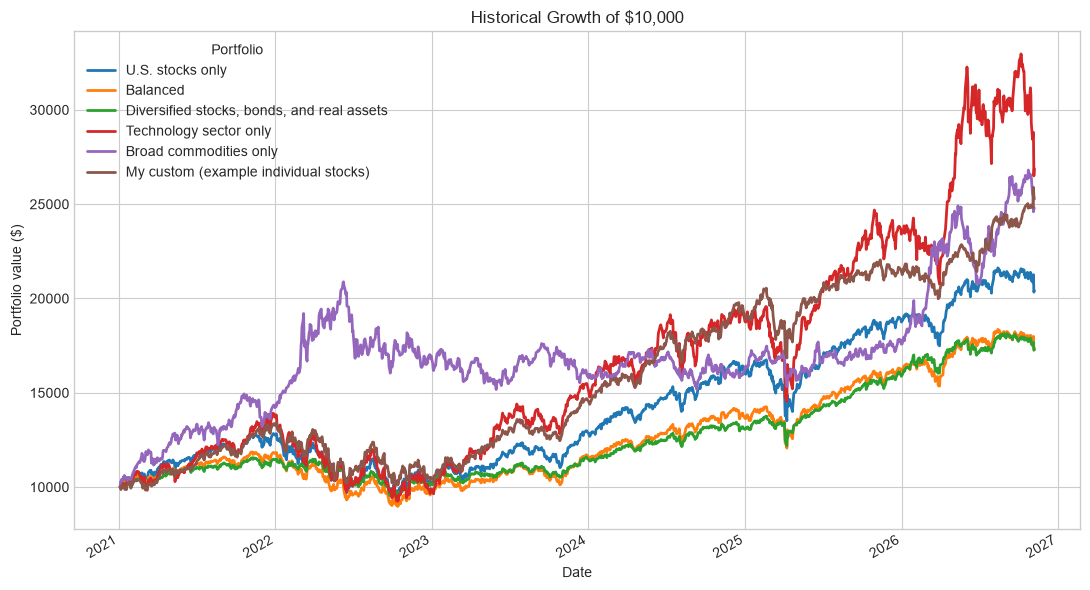

In [5]:
fig, ax = plt.subplots(figsize=(11, 6))
portfolio_values.plot(ax=ax, linewidth=2)
ax.set_title(f"Historical Growth of ${INITIAL_INVESTMENT:,.0f}")
ax.set_xlabel("Date")
ax.set_ylabel("Portfolio value ($)")
ax.legend(title="Portfolio")
plt.tight_layout()
plt.show()

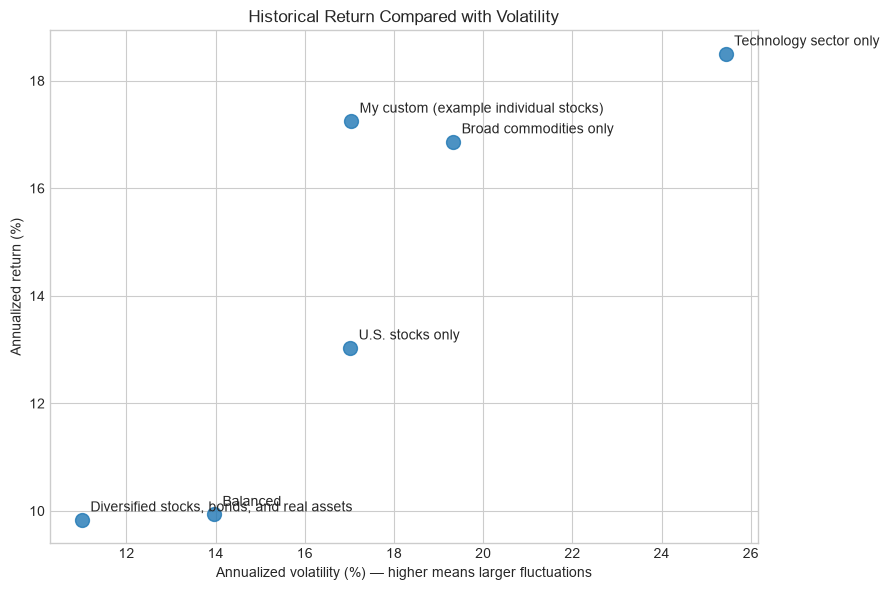

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    summary["Annualized volatility (%)"],
    summary["Annualized return (%)"],
    s=100,
    alpha=0.8,
)

for portfolio_name, row in summary.iterrows():
    ax.annotate(
        portfolio_name,
        (row["Annualized volatility (%)"], row["Annualized return (%)"]),
        xytext=(6, 6),
        textcoords="offset points",
    )

ax.set_title("Historical Return Compared with Volatility")
ax.set_xlabel("Annualized volatility (%) — higher means larger fluctuations")
ax.set_ylabel("Annualized return (%)")
plt.tight_layout()
plt.show()

## 5. Interpret the results

### Results and interpretation

1. **Highest ending value:** The technology-only portfolio ended at USD 26,883.01. The lowest ending value was the diversified stocks, bonds, and real assets mix at USD 17,272.59, a difference of USD 9,610.42. These hypothetical values start from an investment of USD 10,000 and cover **January 4, 2021 through November 6, 2026**.
2. **Highest measured risk:** Technology-only also had the highest annualized volatility (**25.44%**) and the deepest maximum drawdown (**−33.56%**), meaning it fluctuated the most and experienced the largest peak-to-trough decline among these examples.
3. **Effect of adding bonds and other assets:** Compared with the U.S.-stocks-only portfolio, the balanced portfolio (60% VTI, 20% VXUS, 20% BND) had lower annualized volatility (**13.97% vs. 17.02%**) and a slightly smaller maximum drawdown (**−24.25% vs. −25.36%**), but also a lower total return (**73.66% vs. 104.14%**). The more diversified mix had still lower volatility (**11.01%**) and drawdown (**−17.57%**), while its total return was **72.73%**. In this historical period, these mixes traded some growth for less fluctuation and smaller peak-to-trough declines.
4. **Limitation:** This is one historical window, and the result depends on the selected dates and assets. The portfolios are not rebalanced, and the calculation does not account for taxes, fees, inflation, or transaction costs; past performance does not predict future results.

## Briefing / conclusion

From January 4, 2021 through November 6, 2026, a hypothetical 10,000-dollar investment grew to USD 26,883 in the technology-only example, compared with USD 17,273 in the diversified stocks, bonds, and real assets mix. The technology-only portfolio also had the highest annualized volatility (25.44%) and largest maximum drawdown (−33.56%), while the diversified mix had lower volatility (11.01%) and a smaller maximum drawdown (−17.57%). In this period, the diversified mix experienced less fluctuation and a smaller peak-to-trough loss, but its ending value was lower; these historical results do not predict future performance. Would comparing a different time period or rebalancing the portfolios change this growth-versus-risk tradeoff?